<a href="https://colab.research.google.com/github/anniiexp/MAT422/blob/main/4_1_4_2_Graphs_and_Graph_Modeling_Guidance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 - Section 4.1/4.2: Graphs and Graph Modeling

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

np.set_printoptions(precision=3, suppress=True)

## Topics:

*   Graph basics and adjacency representations
*   Degree and neighbors

*   Graph traversal
*   Graph and graph modeling





# Graph basics and adjacency representations

A graph is a way to describe how things are connected. It has 2 parts: nodes (which are the objects) and edges (which are connections between them). For example, people in friend groups could be nodes, and each friendship could be an edge. In an undirected graph, a connection goes both ways.

An adjacency matrix is a grid where the entry in row $i$ and column $j$ is 1 if those 2 nodes are connected and $0$ if they are not. An adjacency list gives eahc node a list of its neighbors. A node's degree is the number of edges touching it. There are 2 things that can help us check, the adjacency matrix of an undirected graph is always symmetric, meaning it reads the same across the diagonal. Also, the degress always add up to twice the number of edges, because each edge is counted once from each end.

Adjacency matrix:
        Ana   Ben  Cara   Dev   Eli   Fay
  Ana     0     1     1     0     0     0
  Ben     1     0     1     0     0     0
 Cara     1     1     0     1     0     0
  Dev     0     0     1     0     1     1
  Eli     0     0     0     1     0     1
  Fay     0     0     0     1     1     0

Adjacency list:
  Ana: ['Ben', 'Cara']
  Ben: ['Ana', 'Cara']
  Cara: ['Ana', 'Ben', 'Dev']
  Dev: ['Cara', 'Eli', 'Fay']
  Eli: ['Dev', 'Fay']
  Fay: ['Eli', 'Dev']

Degrees: {'Ana': 2, 'Ben': 2, 'Cara': 3, 'Dev': 3, 'Eli': 2, 'Fay': 2}

Check 1 - Matrix is symmetric: True
Check 2 - Handshake Lemma:
  Sum of degrees = 14
  2 x number of edges = 14
  Equal? True

BFS distances (number of steps) from Ana: {'Ana': 0, 'Ben': 1, 'Cara': 1, 'Dev': 2, 'Eli': 3, 'Fay': 3}


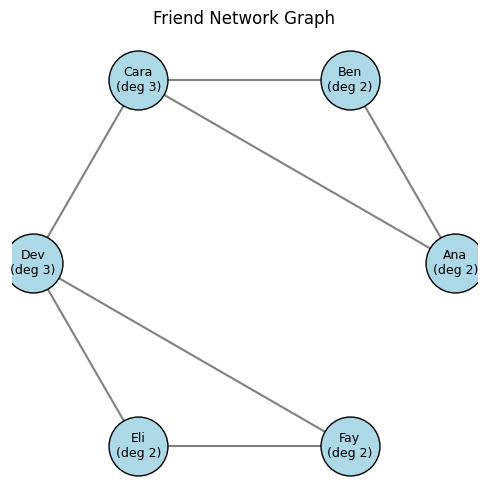

In [15]:
# 1. define the graph: nodes (people) and edges (friendships)
nodes = ["Ana", "Ben", "Cara", "Dev", "Eli", "Fay"]
edges = [("Ana", "Ben"), ("Ana", "Cara"), ("Ben", "Cara"),
         ("Cara", "Dev"), ("Dev", "Eli"), ("Eli", "Fay"), ("Dev", "Fay")]

n = len(nodes)
index = {node: i for i, node in enumerate(nodes)}

# build the adjacency matrix
adj = np.zeros((n, n), dtype=int)
for u, v in edges:
  adj[index[u], index[v]] = 1
  adj[index[v], index[u]] = 1

print("Adjacency matrix:")
print("      " + " ".join(f"{name:>5}" for name in nodes))
for i, name in enumerate(nodes):
    print(f"{name:>5} " + " ".join(f"{val:>5}" for val in adj[i]))

# build the adjacency list
adj_list = {node: [] for node in nodes}
for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

print("\nAdjacency list:")
for node, neighbors in adj_list.items():
    print(f"  {node}: {neighbors}")

# degrees
degrees = {node: int(d) for node, d in zip(nodes, adj.sum(axis=1))}
print("\nDegrees:", degrees)

# checks
print("\nCheck 1 - Matrix is symmetric:", np.array_equal(adj, adj.T))
print("Check 2 - Handshake Lemma:")
print("  Sum of degrees =", sum(degrees.values()))
print("  2 x number of edges =", 2 * len(edges))
print("  Equal?", sum(degrees.values()) == 2 * len(edges))

# use the adjacency list: BFS distances from Ana
def bfs_distances(start):
    dist = {start: 0}
    queue = deque([start])
    while queue:
        current = queue.popleft()
        for neighbor in adj_list[current]:
            if neighbor not in dist:
                dist[neighbor] = dist[current] + 1
                queue.append(neighbor)
    return dist

print("\nBFS distances (number of steps) from Ana:", bfs_distances("Ana"))

# plot the graph (nodes placed evenly on a circle)
angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
pos = {node: (np.cos(a), np.sin(a)) for node, a in zip(nodes, angles)}

plt.figure(figsize=(6, 6))
for u, v in edges:
    plt.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="gray", zorder=1)
for node, (x, y) in pos.items():
    plt.scatter(x, y, s=1800, color="lightblue", edgecolors="black", zorder=2)
    plt.text(x, y, f"{node}\n(deg {degrees[node]})", ha="center", va="center",
             fontsize=9, zorder=3)
plt.title("Friend Network Graph")
plt.axis("equal")
plt.axis("off")
plt.show()

I changed the original 5-node example to a friend network of 6 people with 7 friendships. In the adjacency matrix, a 1 means 2 people are friends. Each row's 1s match that person's adjacency list. For example, Ana's row has 1s under Ben and Cara, and her list is ['Ben', 'Cara']. The matrix is symmetric (Check 1: True) because friendships go both ways. The degrees add up to 14, which is $2 x 7$ edges (Check 2: True), because each friendship is counted once from each person.

The plot shows 2 friend groups, Ana-Ben-Cara and Dev-Eli-Fay, joined by one edge between Cara and Dev. That is why Cara and Dev have the highest degree (3). It also explains the BFS result: Eli and Fay are 3 steps away from Ana, because every path to them has to go through Cara and Dev.

# Degree and Neighbors

In a graph, 2 nodes are neighbors if an edge connects them directly. The degree of a node is how many neighbors it has. Degree tells us how connected a node is. A node with a high degree is connected to many others, and a node with degree 0 is isolated, meaning it has no connections at all. Two formulas come from this. The degrees always add up to twice the number of edges, since each edge gives one neighbor to each of its two ends. The average degree is that total divided by the number of nodes, or 2E / n. We can also use neighbors to explore a graph with breadth-first search (BFS). BFS starts at one node, visits all of its neighbors first, then their neighbors, and so on. This shows which nodes can be reached from the starting point.

Neighbors and degree of each student:
  Mia: neighbors = ['Leo', 'Zoe', 'Sam', 'Ivy'], degree = 4
  Leo: neighbors = ['Mia', 'Zoe'], degree = 2
  Zoe: neighbors = ['Mia', 'Leo'], degree = 2
  Sam: neighbors = ['Mia', 'Ivy'], degree = 2
  Ivy: neighbors = ['Mia', 'Sam', 'Max'], degree = 3
  Max: neighbors = ['Ivy'], degree = 1
  Kai: neighbors = [], degree = 0

Sum of degrees = 14 | 2 x number of edges = 14
Average degree = 2.0
Highest degree: Mia with 4
Isolated students (degree 0): ['Kai']

BFS order from Mia: ['Mia', 'Leo', 'Zoe', 'Sam', 'Ivy', 'Max']
Not reached from Mia: ['Kai']


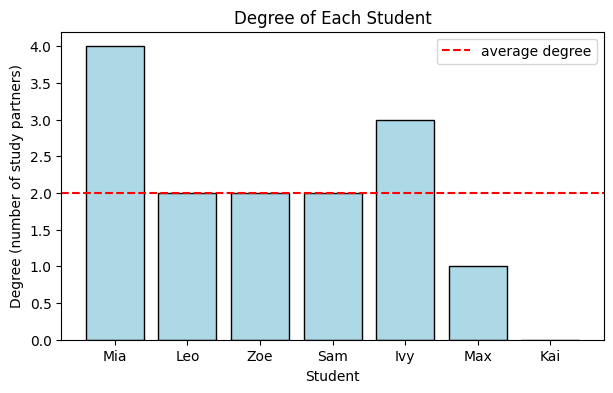

In [16]:
# 1. define the graph: students (nodes) and study-partner pairs (edges)
nodes = ["Mia", "Leo", "Zoe", "Sam", "Ivy", "Max", "Kai"]
edges = [("Mia", "Leo"), ("Mia", "Zoe"), ("Mia", "Sam"), ("Mia", "Ivy"),
         ("Leo", "Zoe"), ("Sam", "Ivy"), ("Ivy", "Max")]

# 2. build the adjacent list (neighbors)
adj_list = {node: [] for node in nodes}
for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

# 3. the degree (number of neighbors)
degree = {node: len(adj_list[node]) for node in nodes}

print("Neighbors and degree of each student:")
for node in nodes:
    print(f"  {node}: neighbors = {adj_list[node]}, degree = {degree[node]}")

# 4. Checks
print("\nSum of degrees =", sum(degree.values()), "| 2 x number of edges =", 2 * len(edges))
print("Average degree =", round(sum(degree.values()) / len(nodes), 2))
print("Highest degree:", max(degree, key=degree.get), "with", max(degree.values()))
print("Isolated students (degree 0):", [node for node in nodes if degree[node] == 0])

# 5. BFS: visit neighbors first, then neighbors of neighbors
def bfs(start):
    seen = {start}
    order = []
    queue = deque([start])
    while queue:
        node = queue.popleft()
        order.append(node)
        for neighbor in adj_list[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                queue.append(neighbor)
    return order

reached = bfs("Mia")
print("\nBFS order from Mia:", reached)
print("Not reached from Mia:", [node for node in nodes if node not in reached])

# 6. Plot: bar chart of each student's degree
plt.figure(figsize=(7, 4))
plt.bar(nodes, [degree[node] for node in nodes], color="lightblue", edgecolor="black")
plt.axhline(np.mean(list(degree.values())), color="red", linestyle="--", label="average degree")
plt.xlabel("Student")
plt.ylabel("Degree (number of study partners)")
plt.title("Degree of Each Student")
plt.legend()
plt.show()

I changed the templates A-E graph to 7 students and their study partners. Each student's degree equals the length of their neighbor list. Mia has the highest degree, and Kai has 0 degrees because he has no study partners. The degrees add up to 14 which is 2 x 7 edges, because each partnership counts once for each student. That gives an average degree of 14/7 = 2.0, shown by the red dashed line in the chart. Mia and Ivy are above the average, Leo, Zoe, and Sam are exactly on it, and Max and Kai are below it.

The BFS from Mia visits her four neighbors first (Leo, Zoe, Sam, Ivy). It then reaches Max, who is Ivy’s neighbor. Kai is never reached, because a node with degree 0 has no edges leading to it.

# Graph Traversal

Graph traversal means visiting the nodes of a graph in an organized way by following its edges, so that every node you can reach gets visited exactly once. The two most common methods are breadth-first search (BFS) and depth-first search (DFS). BFS works in layers. It visits all the neighbors of the starting node first, then the neighbors of those neighbors, and so on, using a queue (first in, first out). Because of this, BFS also finds the fewest number of steps from the start to every other node. DFS goes as deep as it can along one path, then backs up and tries the next path. Both methods visit the same set of nodes, but in a different order.

BFS order from Home: ['Home', 'Park', 'School', 'Store', 'Library', 'Gym', 'Cafe']
BFS distances (steps from Home): {'Home': 0, 'Park': 1, 'School': 1, 'Store': 2, 'Library': 2, 'Gym': 3, 'Cafe': 3}
DFS order from Home: ['Home', 'Park', 'Store', 'School', 'Library', 'Cafe', 'Gym']

Check 1 - Both visit every place once: True
Check 2 - Same places, different order: True | True
Check 3 - BFS distances never decrease in visit order: True


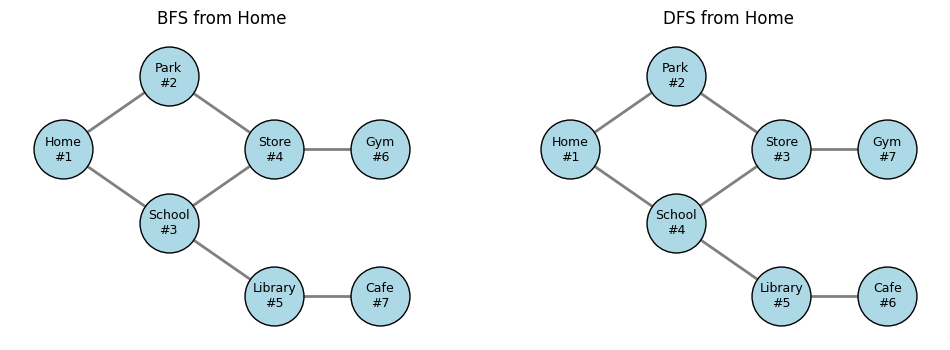

In [17]:
# 1. define the graph: places in a town (nodes) and roads (edges)
nodes = ["Home", "Park", "School", "Store", "Library", "Gym", "Cafe"]
edges = [("Home", "Park"), ("Home", "School"), ("Park", "Store"), ("School", "Store"),
         ("School", "Library"), ("Store", "Gym"), ("Library", "Cafe")]

positions = {
    "Home": (0, 1), "Park": (1, 2), "School": (1, 0), "Store": (2, 1),
    "Library": (2, -1), "Gym": (3, 1), "Cafe": (3, -1),
}

# 2. adjacency list
adj_list = {node: [] for node in nodes}
for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

# 3. BFS: uses a queue, visits level by level, and records distances
def bfs(start):
    dist = {start: 0}
    order = []
    queue = deque([start])
    while queue:
        node = queue.popleft()
        order.append(node)
        for neighbor in adj_list[node]:
            if neighbor not in dist:
                dist[neighbor] = dist[node] + 1
                queue.append(neighbor)
    return order, dist

# 4. DFS: goes as deep as possible before backing up
def dfs(node, seen=None):
    if seen is None:
        seen = []
    seen.append(node)
    for neighbor in adj_list[node]:
        if neighbor not in seen:
            dfs(neighbor, seen)
    return seen

bfs_order, bfs_dist = bfs("Home")
dfs_order = dfs("Home")

print("BFS order from Home:", bfs_order)
print("BFS distances (steps from Home):", bfs_dist)
print("DFS order from Home:", dfs_order)

# 5. Checks
print("\nCheck 1 - Both visit every place once:",
      len(bfs_order) == len(set(bfs_order)) == len(dfs_order) == len(nodes))
print("Check 2 - Same places, different order:",
      set(bfs_order) == set(dfs_order), "|", bfs_order != dfs_order)
print("Check 3 - BFS distances never decrease in visit order:",
      all(bfs_dist[bfs_order[i]] <= bfs_dist[bfs_order[i + 1]] for i in range(len(bfs_order) - 1)))

# 6. Plot both traversals side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, order, title in [(axes[0], bfs_order, "BFS from Home"), (axes[1], dfs_order, "DFS from Home")]:
    for u, v in edges:
        x = [positions[u][0], positions[v][0]]
        y = [positions[u][1], positions[v][1]]
        ax.plot(x, y, color="gray", linewidth=2, zorder=1)
    for step, node in enumerate(order, start=1):
        x, y = positions[node]
        ax.scatter(x, y, s=1800, color="lightblue", edgecolors="black", zorder=2)
        ax.text(x, y, f"{node}\n#{step}", ha="center", va="center", fontsize=9, zorder=3)
    ax.set_title(title)
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(-1.6, 2.6)
    ax.axis("off")
plt.show()

This is a town map with 7 pleaces connected by roads, and ran both BFS and DFS starting from Home. BFS visited the places in layers. First came Home's neighbors, Park and School. Next were Store and Library (2 steps), and last were Gym and Cafe (3 steps). Check 3 printed True, which confirms that BFS never visits a farther place before a closer one. DFS went deep instead. It followed one path from Home through Park, Store, School, Library and all the way to Cafe, then backed up to reach Gym last. Gym was 6th in BFS but 7th in DFS, even though it is only 3 steps from Home. Checks 1 and 2 confirm that both methods visited all 7 places exactly once, just in a different order.

# Graph and Graph Modeling

Graph modeling means using a graph to represent a real-world situation to study it with math. To build a model, we decide what the nodes and edges stand for. In this section, the nodes are people and an edge means 2 people have close context. We can also give each node extra information, like whether that person is infected or susceptible. With this model, we can measure each susceptible person's risk score: the fraction of their contracts who are infected.

The risk score = (number of infected neighbors) / (total number of neighbors)

The score is always between 0 and 1. A score of 0 means none of the person's contacts are infected, and a score of 1 means all of them are. This is a simplifed model, but it shows how a graph turns a real situation into numbers we can compare.

Risk score for each susceptible person (highest first):
  Hana: 1 infected of 1 contacts -> risk = 1.000
  Finn: 1 infected of 2 contacts -> risk = 0.500
  Ben: 1 infected of 3 contacts -> risk = 0.333
  Cal: 1 infected of 3 contacts -> risk = 0.333
  Eve: 1 infected of 3 contacts -> risk = 0.333
  Dee: 0 infected of 3 contacts -> risk = 0.000

Check 1 - All scores between 0 and 1: True
Check 2 - Finn by hand: 1 infected (Gus) / 2 contacts = 0.5 -> True
Average risk of susceptible people: 0.417


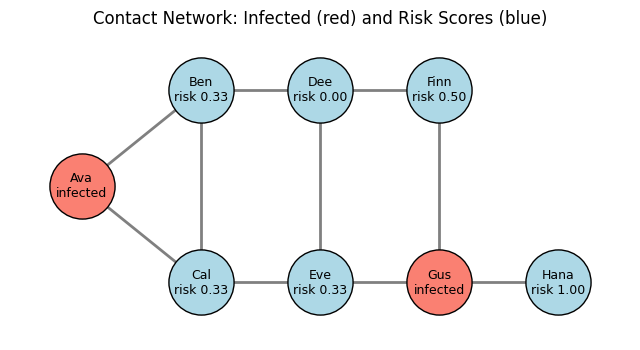

In [18]:
# 1. Model: people (nodes), close contacts (edges), and each person's state
nodes = ["Ava", "Ben", "Cal", "Dee", "Eve", "Finn", "Gus", "Hana"]
edges = [("Ava", "Ben"), ("Ava", "Cal"), ("Ben", "Cal"), ("Ben", "Dee"), ("Cal", "Eve"),
         ("Dee", "Eve"), ("Dee", "Finn"), ("Eve", "Gus"), ("Finn", "Gus"), ("Gus", "Hana")]

infection_state = {node: "susceptible" for node in nodes}
infection_state["Ava"] = "infected"
infection_state["Gus"] = "infected"

positions = {"Ava": (0, 2), "Ben": (1, 3), "Cal": (1, 1), "Dee": (2, 3),
             "Eve": (2, 1), "Finn": (3, 3), "Gus": (3, 1), "Hana": (4, 1)}

# 2. adjacency list
adj_list = {node: [] for node in nodes}
for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

# 3. the risk score = infected neighbors / total neighbors (for susceptible people)
risk_scores = {}
infected_count = {}
for node in nodes:
    if infection_state[node] == "susceptible":
        infected_count[node] = sum(infection_state[n] == "infected" for n in adj_list[node])
        risk_scores[node] = infected_count[node] / max(1, len(adj_list[node]))

print("Risk score for each susceptible person (highest first):")
for node in sorted(risk_scores, key=risk_scores.get, reverse=True):
    print(f"  {node}: {infected_count[node]} infected of {len(adj_list[node])} contacts -> risk = {risk_scores[node]:.3f}")

# 4. checks
print("\nCheck 1 - All scores between 0 and 1:", all(0 <= r <= 1 for r in risk_scores.values()))
print("Check 2 - Finn by hand: 1 infected (Gus) / 2 contacts = 0.5 ->", risk_scores["Finn"] == 0.5)
print("Average risk of susceptible people:", round(np.mean(list(risk_scores.values())), 3))

# 5. plot the contact network
plt.figure(figsize=(8, 4))
for u, v in edges:
    x = [positions[u][0], positions[v][0]]
    y = [positions[u][1], positions[v][1]]
    plt.plot(x, y, color="gray", linewidth=2, zorder=1)
for node, (x, y) in positions.items():
    if infection_state[node] == "infected":
        color = "salmon"
        label = f"{node}\ninfected"
    else:
        color = "lightblue"
        label = f"{node}\nrisk {risk_scores[node]:.2f}"
    plt.scatter(x, y, s=2200, color=color, edgecolors="black", zorder=2)
    plt.text(x, y, label, ha="center", va="center", fontsize=9, zorder=3)
plt.title("Contact Network: Infected (red) and Risk Scores (blue)")
plt.xlim(-0.6, 4.6)
plt.ylim(0.4, 3.6)
plt.axis("off")
plt.show()

This is a contact network of 8 people, with Ava and Gus starting as infected. Each susceptible person's risk score is the fraction of their contacts who are infected. Hana has the highest risk because her only contact, Gus, is infected. Dee has a risk of 0.000 because none of her three contacts (Ben, Eve and Finn) are infected, even though she sits in the middle of the network. Ben and Hana both have exactly 1 infected contact, but Ben’s risk is only 0.333 because he also has 2 healthy contacts. The checks confirmed that every score is between 0 and 1. They also confirmed that Finn’s score matches the hand calculation of 1/2 = 0.5. The average risk across the six susceptible people is 0.417.

The risk score depends on 2 things: how many infected neighbors a person has and how many neighbors they have in total. That is why the same number of infected contacts can give very different risk scores. This shows how a graph model turns a real situation into numbers that we can compare.

# Reflection



*   Graph basics and adjacency representations: Built a friend network of 6 people and showed it as both an adjacency matrix and an adjacency list. I checked that the matrix was symmetric and that the degrees added up to twice the number of edges.

*   Degree and neighbors: Modeled 7 students and their study partners and found each student’s neighbors and degree. I learned that an isolated node like Kai has degree 0 and can’t be reached by BFS.
*   Graph traversal: Ran BFS and DFS on a town map and compared them. Both visited every place, but BFS went level by level and found the fewest steps, while DFS went deep along one path first.


*   Graph and graph modeling: I used a contact network to calculate infection risk scores. I saw that risk depends on both the number of infected contacts and the total number of contacts.

